# Multiple regression: more than one $x$

So far each model had one predictor. Real outcomes depend on many things. **Multiple regression** puts more than one predictor in the same model.

This follows Chapter 10 of [*Elements of Data Science*](https://allendowney.github.io/ElementsOfDataScience/10_regression.html) by Allen Downey.

## Setup

In [1]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──


✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.0.1 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 


── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Learn how to get started at https://www.tidymodels.org/start/


## The data

Load the GSS data set. Keep people under 90 (in the GSS, 89 means "89 or older") and drop rows with missing values.

In [2]:
gss = read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss <- gss |>
    filter(age < 90) |>
    drop_na(realinc, educ, age)

gss |> glimpse()

Rows: 67,293
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


## One predictor

Start with the model from lecture 08: income as a function of education.

In [3]:
fit_educ <- linear_reg() |> fit(realinc ~ educ, data = gss)

tidy(fit_educ)

  term        estimate   std.error statistic p.value      
1 (Intercept) -14441.816 466.64940 -30.94789 7.990275e-209
2 educ          3574.106  34.52202 103.53120  0.000000e+00

Each year of education goes with about \$3,600 more income.

## Two predictors

Put `age` in the formula with a `+`:

$$ \text{realinc} = a_1 + a_2 \times \text{educ} + a_3 \times \text{age} $$

In [4]:
fit_two <- linear_reg() |> fit(realinc ~ educ + age, data = gss)

tidy(fit_two)

  term        estimate     std.error  statistic  p.value      
1 (Intercept) -16779.33806 583.656650 -28.748645 1.174381e-180
2 educ          3602.92314  34.780741 103.589601  0.000000e+00
3 age             42.37839   6.359178   6.664131  2.682812e-11

Now each slope has a new meaning. It is the change in income for one additional unit **when the other predictor stays the same**.

- `educ`: compare two people of the **same age**. One has one more year of school. We expect about \$3,600 more income.
- `age`: compare two people with the **same education**. One is one year older. We expect only about \$40 more income.

Is age really so small? Look at the data.

## Income and age

Find the mean income at each age. (Like in lecture 11, this is for plotting only. The model uses every person.)

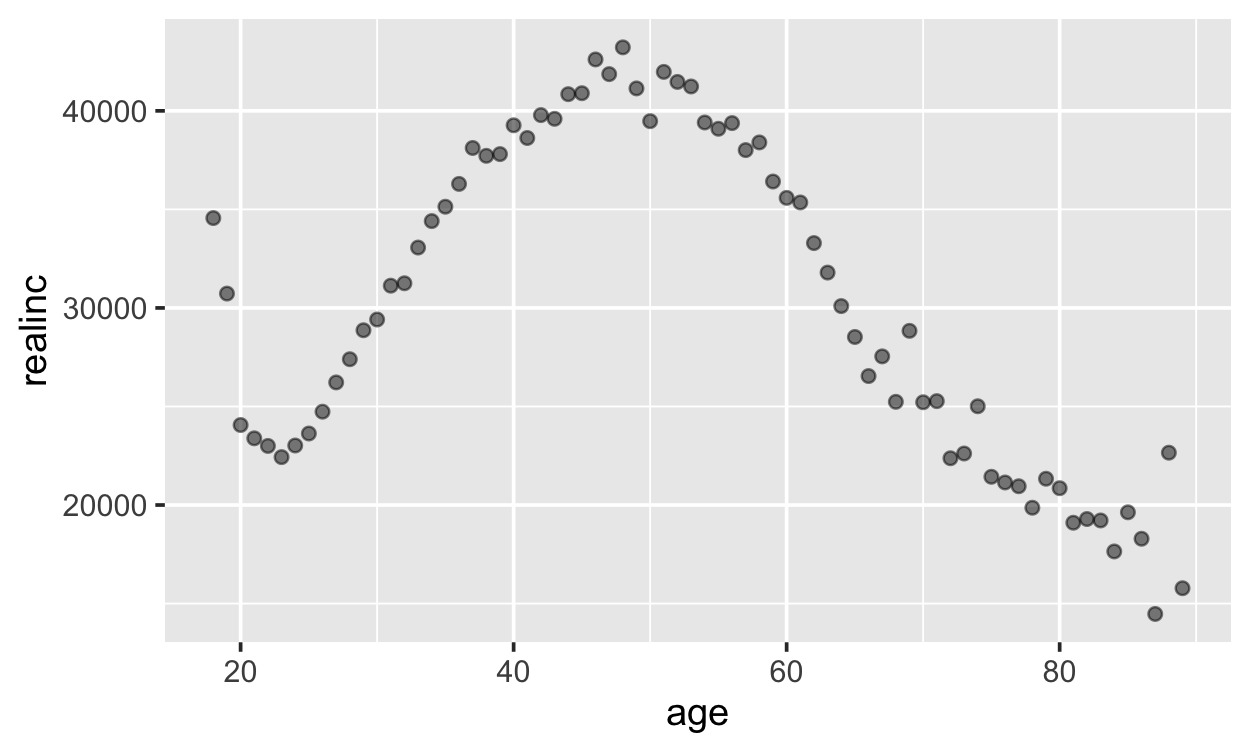

In [5]:
income_by_age <- gss |>
    group_by(age) |>
    summarize(realinc = mean(realinc))

p_age <- ggplot(income_by_age, aes(x = age, y = realinc)) +
    geom_point(alpha = 0.5)

p_age

Income goes up from 20 to about 50. Then it goes down.

A straight line cannot show "up, then down". The best line is almost flat. That is why the `age` slope is so small. The age effect is not small. It is the wrong **shape**.

## Add a curve

Add $\text{age}^2$, like in lecture 10. In a formula, we write it as `I(age^2)`.

$$ \text{realinc} = a_1 + a_2 \times \text{educ} + a_3 \times \text{age} + a_4 \times \text{age}^2 $$

In [6]:
fit_curve <- linear_reg() |> fit(realinc ~ educ + age + I(age^2), data = gss)

tidy(fit_curve)

  term        estimate     std.error   statistic p.value
1 (Intercept) -50854.95163 908.1049035 -56.00119 0      
2 educ          3411.12298  34.4194769  99.10444 0      
3 age           1734.48826  35.5079818  48.84784 0      
4 I(age^2)       -17.09385   0.3531022 -48.41049 0      

The `age` slope went from about 40 to about 1,700. The `age^2` slope is negative. That makes the curve bend down.

These numbers are hard to read alone. Remember lecture 10: with a curve, the marginal effect of age **depends on age**. So do not stare at the parameters. **Look at the predictions.**

## Education is curved too

Do the same thing for education. Find the mean income at each level of education.

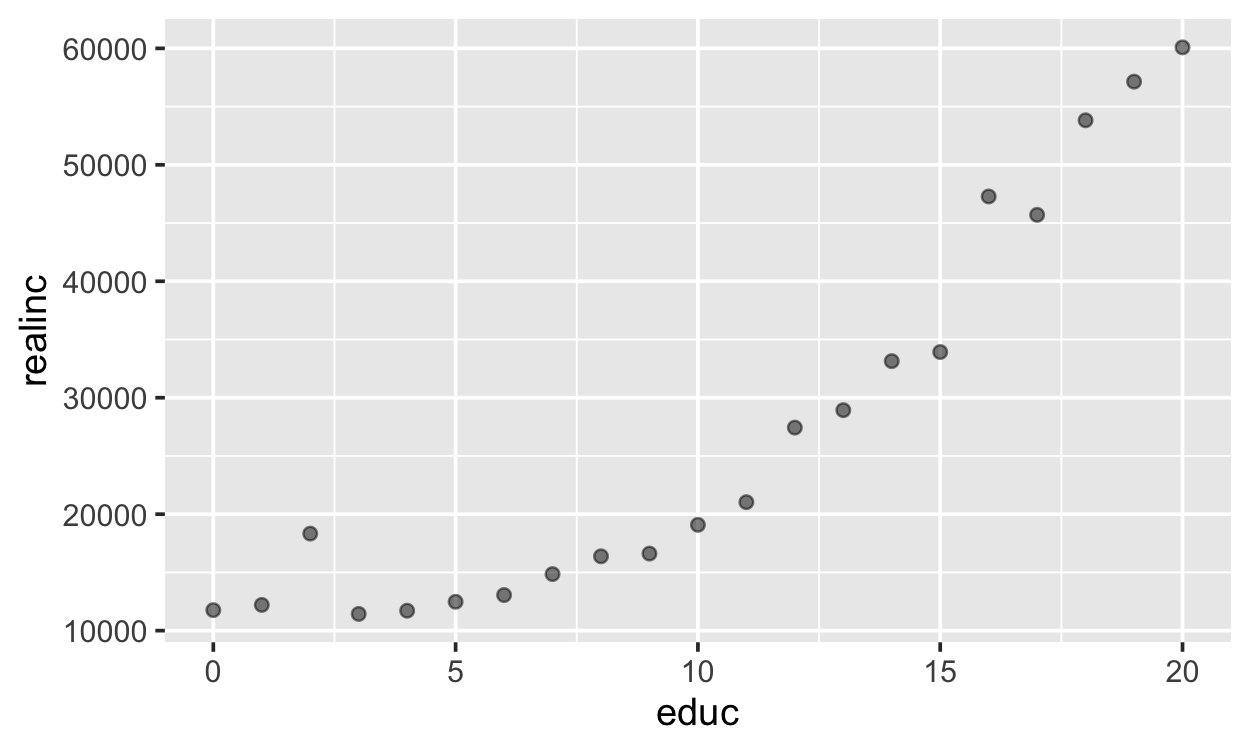

In [7]:
income_by_educ <- gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc))

p_educ <- ggplot(income_by_educ, aes(x = educ, y = realinc)) +
    geom_point(alpha = 0.5)

p_educ

This is not a straight line either. Income goes up slowly up to about 10 years. Then it goes up faster and faster. One more year of college goes with more income than one more year of grade school.

So give education a curve too: add `I(educ^2)`.

In [8]:
fit_full <- linear_reg() |> fit(realinc ~ educ + I(educ^2) + age + I(age^2), data = gss)

tidy(fit_full)

  term        estimate     std.error    statistic  p.value      
1 (Intercept) -25247.20953 1361.9987958 -18.536881  1.615724e-76
2 educ          -642.66143  164.8846444  -3.897643  9.722764e-05
3 I(educ^2)      160.81908    6.3984417  25.134102 9.247620e-139
4 age           1684.83794   35.3978914  47.597127  0.000000e+00
5 I(age^2)       -16.85407    0.3515883 -47.936932  0.000000e+00

Now the `educ` slope is **negative**! Does more school mean less income? No. The `educ^2` slope is positive, and it wins when `educ` is big. Together they make a curve that goes up faster and faster.

This is the same lesson again: **look at the predictions.**

## Predictions by age

Make a grid with every age from 18 to 85, for three education levels:

- 12 years: high school
- 14 years: associate degree
- 16 years: bachelor's degree

`crossing()` makes every combination of the values you give it. You can also give it a whole tibble. Here, each `educ` stays with its `level` name.

In [9]:
levels <- tibble(
    educ = c(12, 14, 16),
    level = factor(c('High school', 'Associate', 'Bachelor'),
                   levels = c('Bachelor', 'Associate', 'High school'))
)

grid_age <- crossing(age = 18:85, levels)

grid_age |> head()

  age educ level      
1 18  12   High school
2 18  14   Associate  
3 18  16   Bachelor   
4 19  12   High school
5 19  14   Associate  
6 19  16   Bachelor   

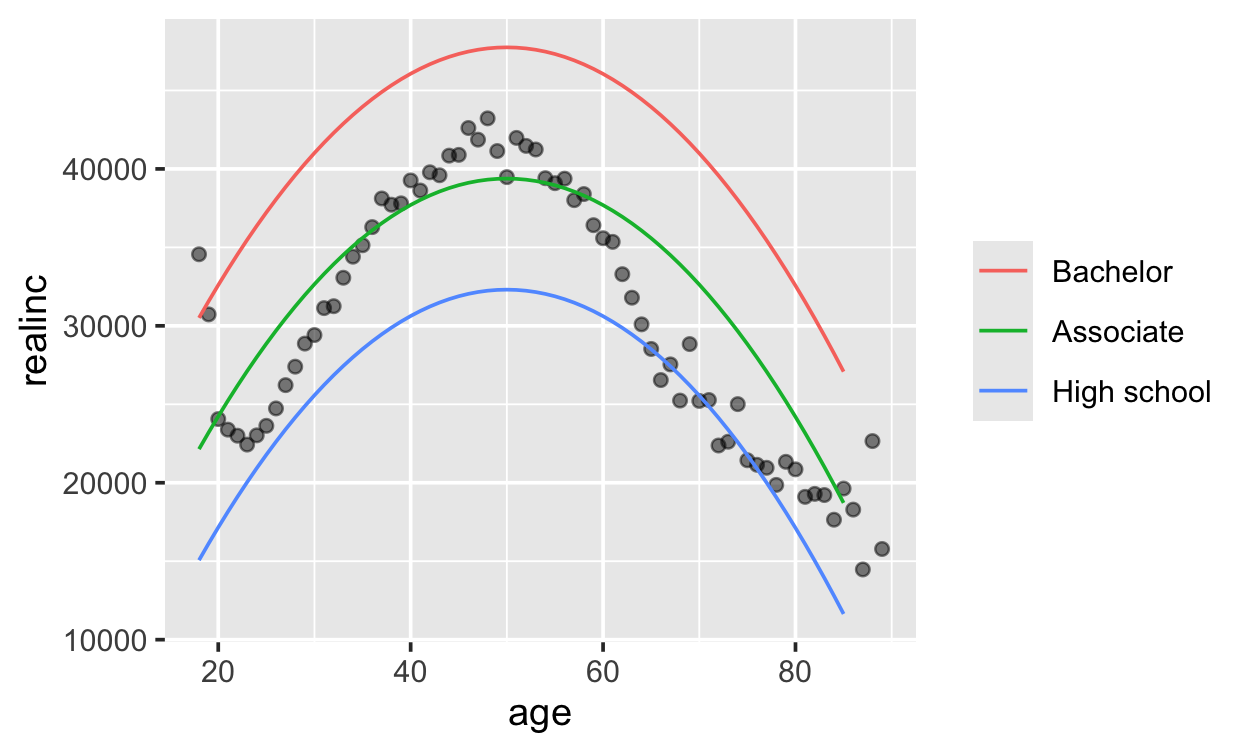

In [10]:
preds_age <- fit_full |>
    predict(new_data = grid_age) |>
    bind_cols(grid_age)

p_age +
    geom_line(data = preds_age, aes(y = .pred, color = level)) +
    labs(color = NULL)

The model gets the shape right: up, then down. It peaks at about age 50.

The three lines have the **same shape**. They are just moved up or down. This is what the `+` means. Each predictor adds its own part. The `educ` part does not change with age. The `age` part does not change with education.

But the gaps are **not equal** now. From high school to associate adds about \$7,100. From associate to bachelor adds about \$8,400. That is the `educ^2` curve at work.

## Predictions by education

Now flip it. Hold `age` at 45 (about the middle age in the data). Let `educ` go from 0 to 20.

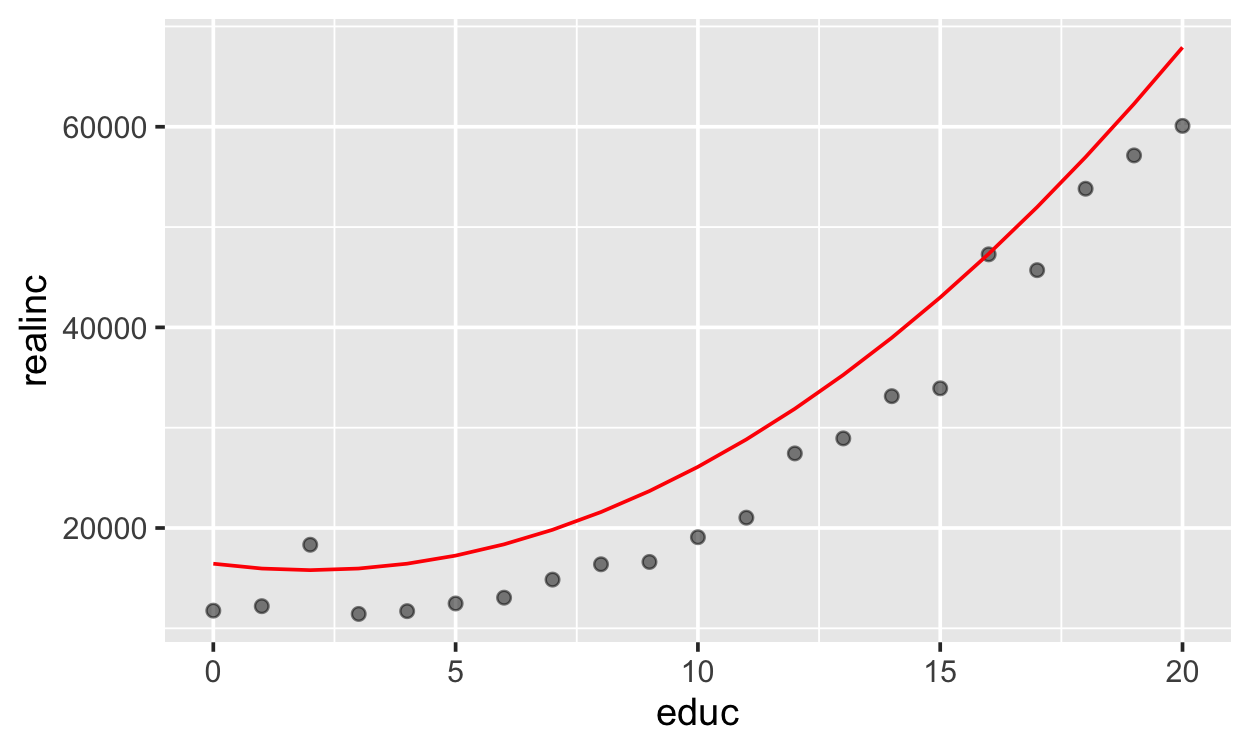

In [11]:
grid_educ <- tibble(educ = 0:20, age = 45)

preds_educ <- fit_full |>
    predict(new_data = grid_educ) |>
    bind_cols(grid_educ)

p_educ +
    geom_line(data = preds_educ, aes(y = .pred), color = 'red')

The curve has the right **shape**: slow on the left, fast on the right.

But it sits above the points. Why? Each point is a mean over people of **all** ages. The line is for people of age 45 only, near the top of the age curve. Try `age = 25` or `age = 70` and see the line move down.

The points on the far left jump around. Few people have so little school, so each mean is from a small group.

## The average marginal effect of education

With `educ^2` in the model, the marginal effect of education **depends on `educ`**. It is small on the left of the curve and big on the right. But sometimes you want **one number**.

The **average marginal effect** (AME) gives one number. It uses the same three steps as in exercise 10:

1. For each person, predict income at their own `educ`.
2. Predict again at `educ + 1`. Keep everything else, like `age`, the same.
3. Subtract. Then take the mean over all people.

In [12]:
gss_plus <- gss |> mutate(educ = educ + 1)

me_educ <- tibble(
    educ = gss$educ,
    pred = predict(fit_full, new_data = gss)$.pred,
    pred_plus = predict(fit_full, new_data = gss_plus)$.pred
) |>
    mutate(me = pred_plus - pred)

me_educ |> head()

  educ pred     pred_plus me      
1 16   35475.36 40139.73  4664.368
2 10   19761.82 22496.36  2734.539
3 12   32239.26 35617.07  3377.816
4 17   43508.27 48494.28  4986.006
5 12   30259.94 33637.75  3377.816
6 14   29688.51 33709.60  4021.092

In [13]:
me_educ |> summarize(ame = mean(me))

  ame     
1 3745.668

On average, one more year of school goes with about **\$3,700** more income.

Compare this with the slope from the one-predictor model, `fit_educ`: about \$3,600. They are close. The curve changes *where* the effect is big, but the average stays about the same.

Look at how the marginal effect changes with `educ`:

In [14]:
me_educ |>
    group_by(educ) |>
    summarize(me = mean(me), n = n())

   educ me        n    
1   0   -481.8423   138
2   1   -160.2042    42
3   2    161.4340   142
4   3    483.0722   235
5   4    804.7103   268
6   5   1126.3485   336
7   6   1447.9866   760
8   7   1769.6248   789
9   8   2091.2630  2414
10  9   2412.9011  1930
11 10   2734.5393  2730
12 11   3056.1775  3584
13 12   3377.8156 19695
14 13   3699.4538  5529
15 14   4021.0920  7764
16 15   4342.7301  3164
17 16   4664.3683  9685
18 17   4986.0065  2338
19 18   5307.6446  2907
20 19   5629.2828  1059
21 20   5950.9210  1784

It goes from about -\$500 at 0 years to about \$6,000 at 20 years. The AME is the mean of these numbers, weighted by how many people are at each level. Look at the `n` column. Most people have 12 or more years of school, so the AME is near the marginal effect at 12 to 13 years.

Notice: every person gets the same `me` for the same `educ`, at any age. Why? `age` is **added** in the model. When we change only `educ`, the `age` part is the same in both predictions, and it cancels.